<a href="https://colab.research.google.com/github/Teja12349/ITA0616-ML/blob/main/Problem-04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANN RESULTS TABLE
 Input 1  Input 2  Expected Output  Predicted Output
       0        0                0                 0
       0        1                1                 1
       1        0                1                 1
       1        1                0                 0


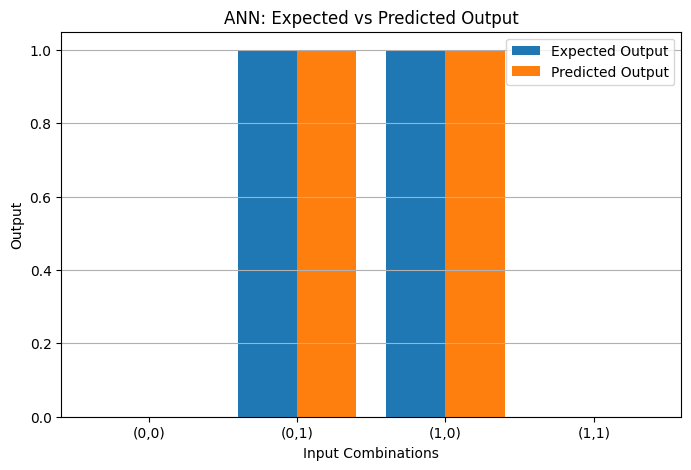

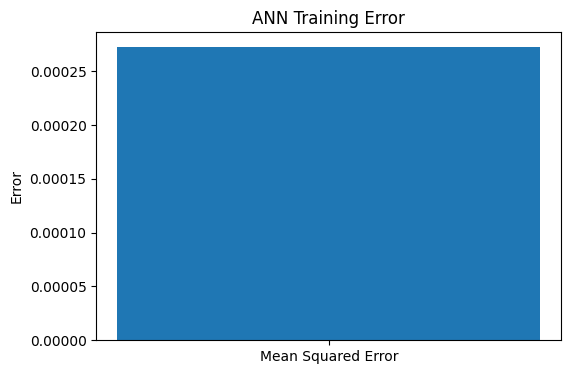

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
Y = np.array([[0], [1], [1], [0]])
np.random.seed(42)
W1 = np.random.rand(2, 4)
W2 = np.random.rand(4, 1)
b1 = np.zeros((1, 4))
b2 = np.zeros((1, 1))
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
lr = 0.5
for epoch in range(10000):
    H = sigmoid(np.dot(X, W1) + b1)
    O = sigmoid(np.dot(H, W2) + b2)
    error = Y - O
    dO = error * O * (1 - O)
    dH = dO.dot(W2.T) * H * (1 - H)
    W2 += lr * H.T.dot(dO)
    b2 += lr * np.sum(dO, axis=0, keepdims=True)
    W1 += lr * X.T.dot(dH)
    b1 += lr * np.sum(dH, axis=0, keepdims=True)
H = sigmoid(np.dot(X, W1) + b1)
O = sigmoid(np.dot(H, W2) + b2)
predicted = (O >= 0.5).astype(int)
table = pd.DataFrame({
    "Input 1": X[:, 0],
    "Input 2": X[:, 1],
    "Expected Output": Y.flatten(),
    "Predicted Output": predicted.flatten()
})
print("ANN RESULTS TABLE")
print(table.to_string(index=False))
plt.figure(figsize=(8, 5))
x = np.arange(len(X))
plt.bar(x - 0.2, Y.flatten(), 0.4, label="Expected Output")
plt.bar(x + 0.2, predicted.flatten(), 0.4, label="Predicted Output")
plt.xticks(x, ["(0,0)", "(0,1)", "(1,0)", "(1,1)"])
plt.xlabel("Input Combinations")
plt.ylabel("Output")
plt.title("ANN: Expected vs Predicted Output")
plt.legend()
plt.grid(axis="y")
plt.show()
H = sigmoid(np.dot(X, W1) + b1)
O = sigmoid(np.dot(H, W2) + b2)
error = np.mean((Y - O) ** 2)
plt.figure(figsize=(6, 4))
plt.bar(["Mean Squared Error"], [error])
plt.ylabel("Error")
plt.title("ANN Training Error")
plt.show()